### Лабораторна робота №2
Логістична регресія та федеративне навчання
Датасет: Dry Bean Dataset (13 611 об'єктів, 16 числових ознак, 7 класів).

Мета: реалізувати багатокласову логістичну регресію засобами NumPy, порівняти централізоване та федеративне навчання FedAvg, дослідити IID / Non-IID розподіли та вплив кількості локальних епох.

### 1. Імпорт бібліотек і завантаження даних
Dry Bean підходить для федеративного навчання: датасет має достатньо прикладів для розподілу між клієнтами, 16 числових характеристик зерен і 7 цільових класів. 


In [ ]:
import os
import zipfile
import urllib.request
from pathlib import Path
#імпортуємо усі потрібні бібліотеки для роботи з даними
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    log_loss, confusion_matrix, classification_report
)
# Фіксуємо генератор випадкових чисел для відтворюваності експериментів.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Визначаємо шлях до файлу з набором даних.
DATA_FILE = Path("Dry_Bean_Dataset.xlsx")

if not DATA_FILE.exists():
    archive_path = Path("DryBeanDataset.zip")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.zip"
    print("Завантаження Dry Bean Dataset з UCI...")
    urllib.request.urlretrieve(url, archive_path)
    with zipfile.ZipFile(archive_path, "r") as archive:
        archive.extractall(".")
    DATA_FILE = Path("DryBeanDataset") / "Dry_Bean_Dataset.xlsx"

df = pd.read_excel(DATA_FILE)
print("Розмір датасету:", df.shape)
display(df.head())

Завантаження Dry Bean Dataset з UCI...
Розмір датасету: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


#### Висновок.
 Було імпортовано необхідні бібліотеки та завантажено набір даних Dry Bean Dataset. Дані містять числові характеристики зерен і цільову змінну Class, яка визначає один із семи типів квасолі. Обраний набір даних підходить для реалізації багатокласової логістичної регресії та експериментів із федеративним навчанням. На наступному етапі необхідно перевірити структуру даних, типи ознак, пропущені значення та розподіл класів.

### 2. EDA- первинний аналіз даних
Перевіряємо структуру, типи стовпців, пропущені значення, розподіл класів, описову статистику та кореляції числових ознак.

Типи даних:


,dtype
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


Пропущені значення:


,missing
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Кількість дублікатів: 68
Описова статистика:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


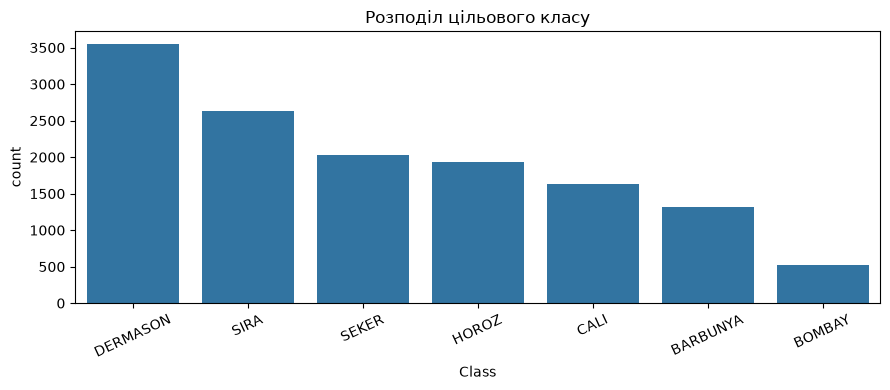

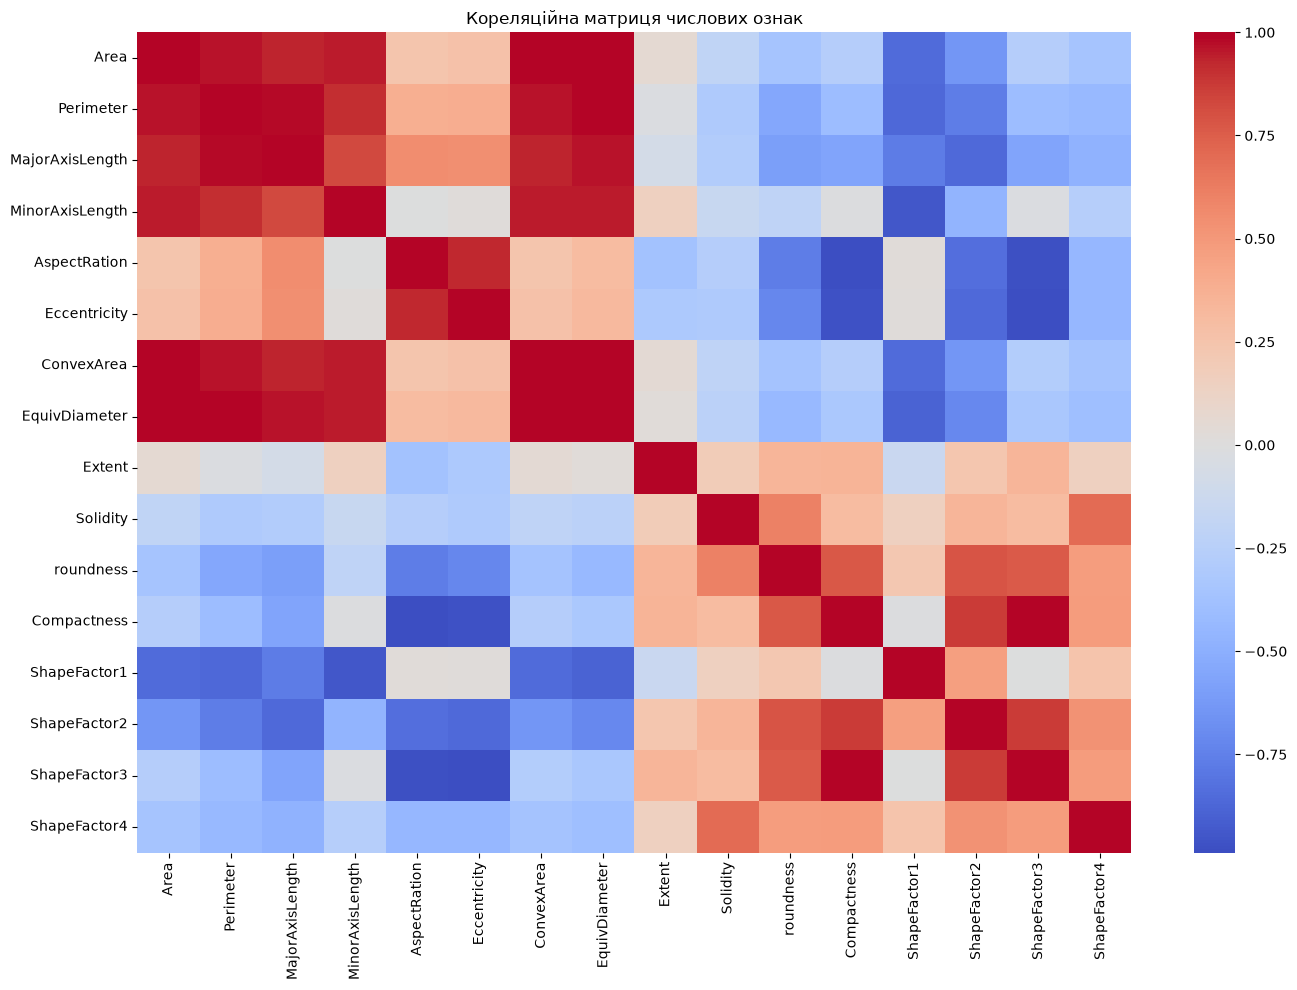

In [3]:
print("Типи даних:")
display(df.dtypes.to_frame("dtype"))

print("Пропущені значення:")
display(df.isna().sum().to_frame("missing"))

print("Кількість дублікатів:", df.duplicated().sum())

print("Описова статистика:")
display(df.describe().T)

class_counts = df["Class"].value_counts()
display(class_counts.to_frame("count"))

plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="Class", order=class_counts.index)
plt.title("Розподіл цільового класу")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(14, 10))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0)
plt.title("Кореляційна матриця числових ознак")
plt.tight_layout()
plt.show()

### Висновок за EDA
Датасет містить 16 числових ознак і одну категоріальну цільову змінну Class. Категоріальних вхідних ознак немає, тому One-Hot / Ordinal / Target Encoding для X не потрібні. Класи представлені нерівномірно, отже крім accuracy використовуємо macro-F1 та balanced accuracy. Сильні кореляції між геометричними характеристиками можуть свідчити про мультиколінеарність; Ridge-регуляризація допомагає стабілізувати оцінки ваг.

### 3. Розбиття на Global Test, Global Validation і FL Train Pool
Спочатку відокремлюємо 20% Global Test. Із решти 80% виділяємо 12.5% від початкової вибірки для Global Validation (це 10% усіх даних). У результаті FL Train Pool становить 70%.

Data Leakage - це потрапляння інформації з валідаційної або тестової вибірки в навчальний процес чи підготовку даних. Щоб уникнути цього, тестова вибірка не використовується для відбору ознак, масштабування або підбору гіперпараметрів.

In [4]:
X_all = df.drop(columns=["Class"]).copy()
y_text = df["Class"].copy()

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_
num_classes = len(class_names)

X_train_pool_df, X_test_df, y_train_pool, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all,
    random_state=RANDOM_STATE
)
X_train_pool_df, X_val_df, y_train_pool, y_val = train_test_split(
    X_train_pool_df, y_train_pool, test_size=0.125,
    stratify=y_train_pool, random_state=RANDOM_STATE
)

print("FL Train Pool:", X_train_pool_df.shape)
print("Global Validation:", X_val_df.shape)
print("Global Test:", X_test_df.shape)

FL Train Pool: (9527, 16)
Global Validation: (1361, 16)
Global Test: (2723, 16)


### 4. Відбір ознак і масштабування
Для вибору ознак використовуємо лише FL Train Pool. Оскільки ціль має 7 класів, застосовуємо ANOVA F-test (f_classif) для оцінювання зв'язку кожної ознаки з класом. Відбираємо 12 найінформативніших ознак. Це допоміжний інструмент scikit-learn; сама модель і її навчання реалізовані на NumPy.

Стандартизація: \(x'=(x-\mu)/\sigma\). Середні та стандартні відхилення обчислюються лише на FL Train Pool. Такий спрощений варіант масштабування прямо дозволений інструкцією для симуляції.

In [5]:
f_scores, p_values = f_classif(X_train_pool_df, y_train_pool)
feature_scores = pd.DataFrame({
    "feature": X_train_pool_df.columns,
    "F_score": f_scores,
    "p_value": p_values
}).sort_values("F_score", ascending=False)

display(feature_scores)

N_FEATURES = 12
selected_features = feature_scores.head(N_FEATURES)["feature"].tolist()
print("Відібрані ознаки:", selected_features)

X_pool_raw = X_train_pool_df[selected_features].to_numpy(dtype=np.float64)
X_val_raw = X_val_df[selected_features].to_numpy(dtype=np.float64)
X_test_raw = X_test_df[selected_features].to_numpy(dtype=np.float64)

scaler_mean = X_pool_raw.mean(axis=0)
scaler_std = X_pool_raw.std(axis=0)
scaler_std[scaler_std == 0] = 1.0

X_pool = (X_pool_raw - scaler_mean) / scaler_std
X_val = (X_val_raw - scaler_mean) / scaler_std
X_test = (X_test_raw - scaler_mean) / scaler_std

print("Кількість ознак після відбору:", X_pool.shape[1])

,feature,F_score,p_value
0,Area,20717.386708,0.0
6,ConvexArea,20693.609330,0.0
7,EquivDiameter,17970.526274,0.0
1,Perimeter,17139.487882,0.0
3,MinorAxisLength,15891.276134,0.0
2,MajorAxisLength,15133.234065,0.0
12,ShapeFactor1,8534.731268,0.0
13,ShapeFactor2,8449.688238,0.0
4,AspectRation,7084.226025,0.0
11,Compactness,6945.571643,0.0


Відібрані ознаки: ['Area', 'ConvexArea', 'EquivDiameter', 'Perimeter', 'MinorAxisLength', 'MajorAxisLength', 'ShapeFactor1', 'ShapeFactor2', 'AspectRation', 'Compactness', 'ShapeFactor3', 'Eccentricity']
Кількість ознак після відбору: 12


### 5. Реалізація багатокласової логістичної регресії на NumPy
Модель використовує формули з методички: \(Z=XW+b\), softmax для ймовірностей, крос-ентропію з Ridge-штрафом та міні-батчевий градієнтний спуск. Циклів for за окремими об'єктами для loss або градієнтів немає — усі обчислення векторизовані.

In [6]:
def one_hot(y, n_classes):
    return np.eye(n_classes, dtype=np.float64)[y]


def softmax(z):
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


class NumpySoftmaxRegression:
    def __init__(self, n_features, n_classes, learning_rate=0.05,
                 reg_lambda=0.001, batch_size=256, random_state=42):
        rng = np.random.default_rng(random_state)
        self.W = rng.normal(0, 0.01, size=(n_features, n_classes))
        self.b = np.zeros((1, n_classes))
        self.learning_rate = learning_rate
        self.reg_lambda = reg_lambda
        self.batch_size = batch_size
        self.n_classes = n_classes
        self.history = {"loss": [], "accuracy": []}

    def predict_proba(self, X):
        return softmax(X @ self.W + self.b)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def loss(self, X, y):
        m = len(y)
        Y = one_hot(y, self.n_classes)
        P = self.predict_proba(X)
        ce = -np.sum(Y * np.log(np.clip(P, 1e-12, 1.0))) / m
        ridge = (self.reg_lambda / 2) * np.sum(self.W ** 2)
        return ce + ridge

    def gradients(self, X, y):
        m = len(y)
        Y = one_hot(y, self.n_classes)
        P = self.predict_proba(X)
        error = P - Y
        dW = (X.T @ error) / m + self.reg_lambda * self.W
        db = np.sum(error, axis=0, keepdims=True) / m
        return dW, db

    def update_parameters(self, dW, db):
        self.W -= self.learning_rate * dW
        self.b -= self.learning_rate * db

    def fit(self, X, y, epochs=50, shuffle=True):
        n = len(y)
        for epoch in range(epochs):
            indices = np.random.permutation(n) if shuffle else np.arange(n)
            for start in range(0, n, self.batch_size):
                batch_idx = indices[start:start + self.batch_size]
                X_batch = X[batch_idx]
                y_batch = y[batch_idx]
                dW, db = self.gradients(X_batch, y_batch)
                self.update_parameters(dW, db)

            self.history["loss"].append(self.loss(X, y))
            self.history["accuracy"].append(accuracy_score(y, self.predict(X)))
        return self

    def get_parameters(self):
        return self.W.copy(), self.b.copy()

    def set_parameters(self, parameters):
        self.W = parameters[0].copy()
        self.b = parameters[1].copy()

### 6. Функції оцінювання
Macro-F1 рахує F1 окремо для кожного класу та усереднює значення з однаковою вагою. Balanced accuracy усереднює recall за класами. Log-loss оцінює якість прогнозованих імовірностей.

In [7]:
def evaluate_model(model, X, y):
    probabilities = model.predict_proba(X)
    predictions = np.argmax(probabilities, axis=1)
    return {
        "accuracy": accuracy_score(y, predictions),
        "macro_f1": f1_score(y, predictions, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "log_loss": log_loss(y, probabilities, labels=np.arange(num_classes))
    }


def show_confusion_matrix(model, X, y, title):
    predictions = model.predict(X)
    cm = confusion_matrix(y, predictions, labels=np.arange(num_classes))
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Передбачений клас")
    plt.ylabel("Справжній клас")
    plt.title(title)
    plt.tight_layout()
    plt.show()

### 7. Централізована базова модель і підбір гіперпараметрів
Централізована модель навчається на всьому FL Train Pool. Гіперпараметри вибираються за Global Validation. Global Test залишається недоторканим до фінальної оцінки.

Перевіряємо кілька learning rate, batch size та Ridge-коефіцієнтів. Щоб час виконання був прийнятним, кількість епох під час пошуку обмежена.

,learning_rate,batch_size,lambda,accuracy,macro_f1,balanced_accuracy,log_loss
7,0.08,128,0.0010,0.896400,0.900229,0.896518,0.306995
6,0.08,128,0.0001,0.895665,0.899895,0.896180,0.300190
9,0.08,256,0.0001,0.892726,0.896148,0.892030,0.339369
10,0.08,256,0.0010,0.892726,0.895973,0.892044,0.344495
8,0.08,128,0.0100,0.892726,0.895796,0.890834,0.377366
1,0.03,128,0.0010,0.891256,0.894727,0.890392,0.368678
0,0.03,128,0.0001,0.890522,0.893279,0.889041,0.364255
3,0.03,256,0.0001,0.890522,0.893105,0.888645,0.443615
2,0.03,128,0.0100,0.890522,0.893102,0.888296,0.413943
4,0.03,256,0.0010,0.889052,0.891574,0.887020,0.446770


Найкращі параметри: {'learning_rate': 0.08, 'batch_size': 128, 'reg_lambda': 0.001}


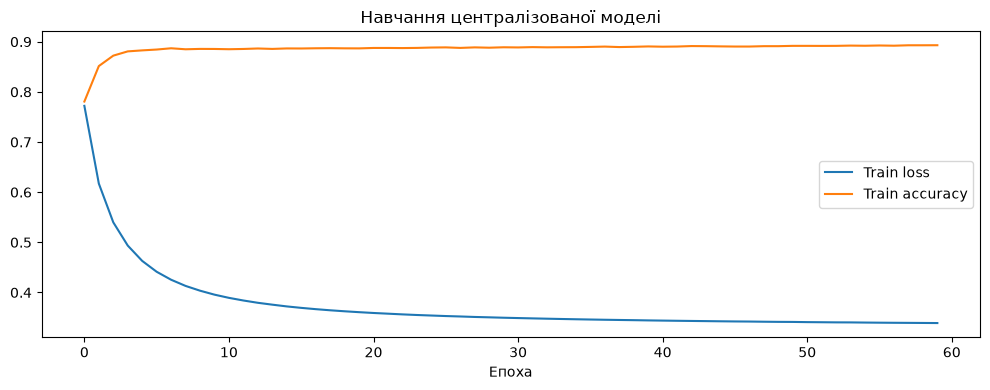

,accuracy,macro_f1,balanced_accuracy,log_loss
Centralized,0.895336,0.905789,0.902599,0.297323


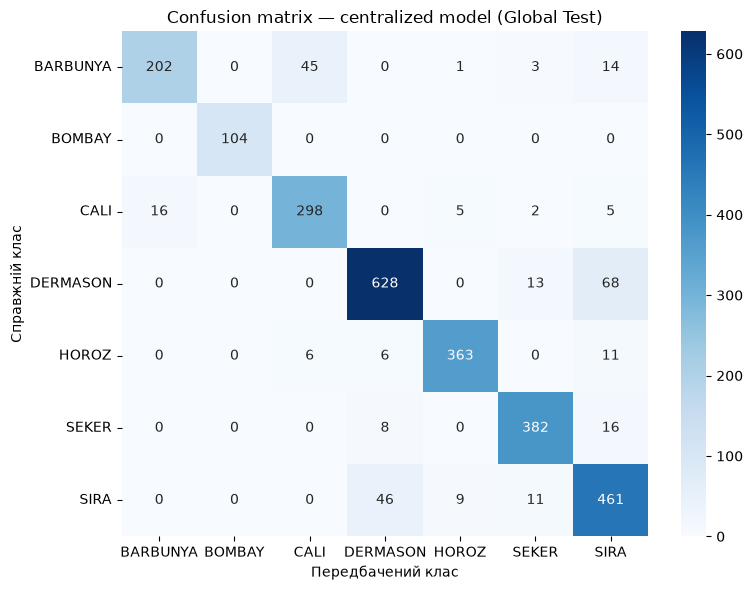

In [8]:
search_results = []
best_score = -np.inf
best_params = None

for lr in [0.03, 0.08]:
    for batch in [128, 256]:
        for reg in [0.0001, 0.001, 0.01]:
            candidate = NumpySoftmaxRegression(
                X_pool.shape[1], num_classes,
                learning_rate=lr, reg_lambda=reg,
                batch_size=batch, random_state=RANDOM_STATE
            )
            candidate.fit(X_pool, y_train_pool, epochs=25)
            val_metrics = evaluate_model(candidate, X_val, y_val)
            search_results.append({
                "learning_rate": lr, "batch_size": batch,
                "lambda": reg, **val_metrics
            })
            if val_metrics["macro_f1"] > best_score:
                best_score = val_metrics["macro_f1"]
                best_params = {"learning_rate": lr, "batch_size": batch,
                               "reg_lambda": reg}

search_df = pd.DataFrame(search_results).sort_values("macro_f1", ascending=False)
display(search_df)
print("Найкращі параметри:", best_params)

central_model = NumpySoftmaxRegression(
    X_pool.shape[1], num_classes, **best_params,
    random_state=RANDOM_STATE
)
central_model.fit(X_pool, y_train_pool, epochs=60)

plt.figure(figsize=(10, 4))
plt.plot(central_model.history["loss"], label="Train loss")
plt.plot(central_model.history["accuracy"], label="Train accuracy")
plt.xlabel("Епоха")
plt.title("Навчання централізованої моделі")
plt.legend()
plt.tight_layout()
plt.show()

central_test_metrics = evaluate_model(central_model, X_test, y_test)
display(pd.DataFrame([central_test_metrics], index=["Centralized"]))
show_confusion_matrix(central_model, X_test, y_test,
                      "Confusion matrix — centralized model (Global Test)")

### 8. Розподіл FL Train Pool між клієнтами
Кожен приклад належить рівно одному клієнту. Сервер не отримує локальні масиви клієнтів: у симуляції функції клієнта працюють із власними індексами/підмасивами, а сервер отримує лише оновлені параметри та кількість локальних прикладів.

Для IID використовуємо стратифіковане розбиття. Для Non-IID — розподіл Діріхле окремо всередині кожного класу.

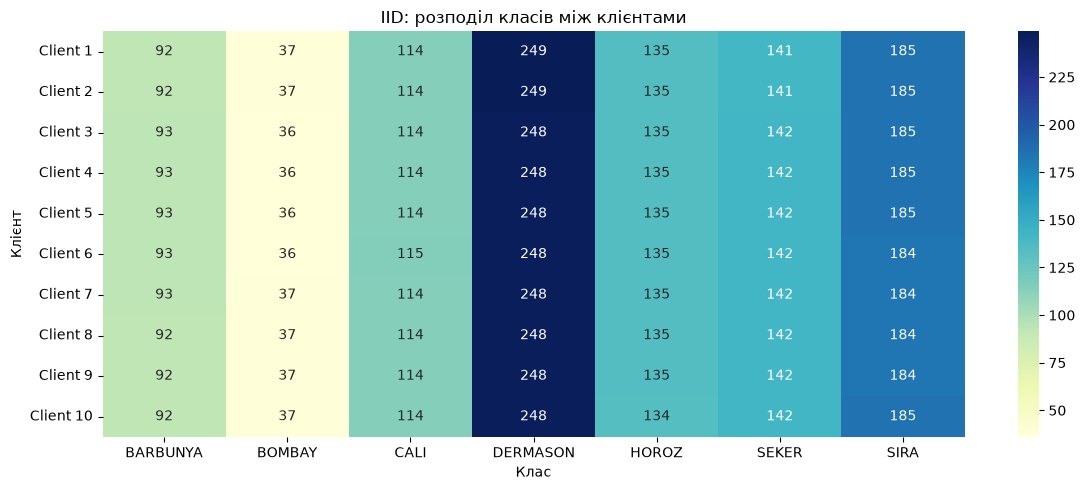

Кількість об'єктів у клієнтів: [953, 953, 953, 953, 953, 953, 953, 952, 952, 952]
Мінімальний розмір клієнта: 952


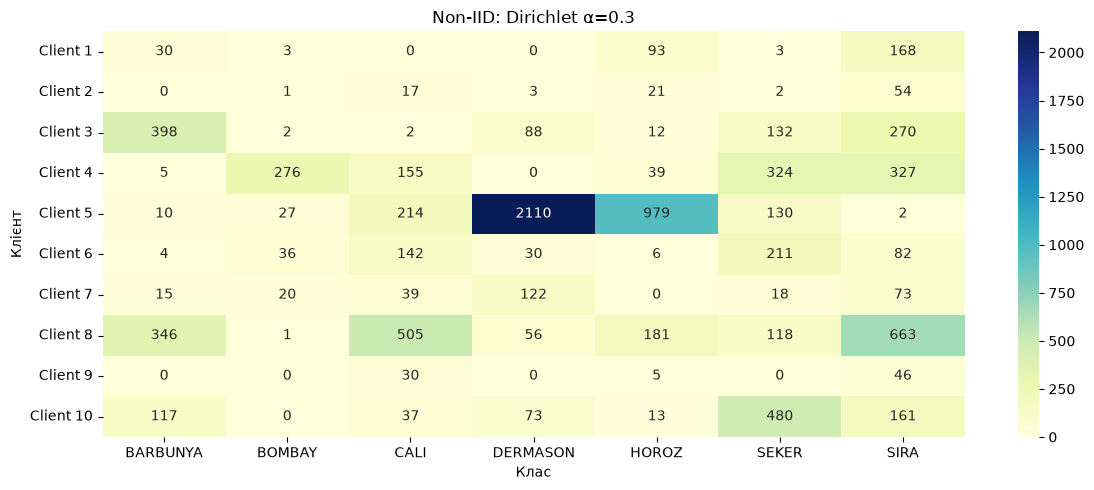

Кількість об'єктів у клієнтів: [297, 98, 904, 1126, 3472, 511, 287, 1870, 81, 881]
Мінімальний розмір клієнта: 81


In [9]:
def make_iid_clients(y, n_clients=10, seed=42):
    splitter = StratifiedKFold(n_splits=n_clients, shuffle=True,
                               random_state=seed)
    return [indices for _, indices in splitter.split(np.zeros(len(y)), y)]


def make_dirichlet_clients(y, n_clients=10, alpha=0.3, seed=42):
    rng = np.random.default_rng(seed)
    client_indices = [[] for _ in range(n_clients)]
    for class_id in np.unique(y):
        class_idx = np.where(y == class_id)[0]
        rng.shuffle(class_idx)
        proportions = rng.dirichlet(np.repeat(alpha, n_clients))
        counts = rng.multinomial(len(class_idx), proportions)
        splits = np.split(class_idx, np.cumsum(counts)[:-1])
        for client_id, part in enumerate(splits):
            client_indices[client_id].extend(part.tolist())
    return [np.array(sorted(indices), dtype=int) for indices in client_indices]


def client_distribution(client_indices, y, n_classes):
    matrix = np.zeros((len(client_indices), n_classes), dtype=int)
    for client_id, indices in enumerate(client_indices):
        matrix[client_id] = np.bincount(y[indices], minlength=n_classes)
    return matrix


def plot_client_distribution(client_indices, y, title):
    matrix = client_distribution(client_indices, y, num_classes)
    plt.figure(figsize=(12, 5))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="YlGnBu",
                xticklabels=class_names,
                yticklabels=[f"Client {i+1}" for i in range(len(client_indices))])
    plt.title(title)
    plt.xlabel("Клас")
    plt.ylabel("Клієнт")
    plt.tight_layout()
    plt.show()
    print("Кількість об'єктів у клієнтів:", [len(x) for x in client_indices])
    print("Мінімальний розмір клієнта:", min(map(len, client_indices)))
    if min(map(len, client_indices)) < 10:
        print("Увага: є клієнт із менш ніж 10 прикладами.")
    return matrix


N_CLIENTS = 10
iid_clients = make_iid_clients(y_train_pool, N_CLIENTS, RANDOM_STATE)
iid_matrix = plot_client_distribution(iid_clients, y_train_pool,
                                       "IID: розподіл класів між клієнтами")

noniid_clients = make_dirichlet_clients(
    y_train_pool, N_CLIENTS, alpha=0.3, seed=RANDOM_STATE
)
noniid_matrix = plot_client_distribution(
    noniid_clients, y_train_pool, "Non-IID: Dirichlet α=0.3"
)

IID означає, що локальні набори приблизно зберігають глобальні пропорції класів. У Non-IID кожен клас розподіляється між клієнтами за окремим вектором Діріхле. За малого α частина клієнтів отримує значно більше прикладів окремих класів, тому локальні задачі стають неоднорідними. Це може ускладнити узгодження локальних оновлень під час агрегації.

### 9. Федеративне навчання FedAvg
У кожному раунді сервер надсилає поточні W і b клієнтам. Клієнт починає з цих параметрів, навчається локально E епох і повертає оновлені параметри. Сервер агрегує їх зваженим середнім за кількістю локальних прикладів.

Важливо: серверу не передаються локальні X та y. У цій навчальній симуляції клієнти представлені окремими локальними підмасивами в пам'яті одного комп'ютера.

In [10]:
def fedavg(parameters_list, sample_counts):
    total = np.sum(sample_counts)
    weights = np.asarray(sample_counts, dtype=np.float64) / total
    W_avg = sum(w * params[0] for w, params in zip(weights, parameters_list))
    b_avg = sum(w * params[1] for w, params in zip(weights, parameters_list))
    return W_avg, b_avg


def federated_train(X, y, client_indices, global_X_val, global_y_val,
                    local_epochs=5, rounds=25, learning_rate=0.05,
                    reg_lambda=0.001, batch_size=256, seed=42):
    global_model = NumpySoftmaxRegression(
        X.shape[1], num_classes, learning_rate=learning_rate,
        reg_lambda=reg_lambda, batch_size=batch_size, random_state=seed
    )
    history = {"round": [], "val_loss": [], "val_accuracy": [],
               "val_macro_f1": []}

    for round_id in range(rounds):
        client_parameters = []
        client_sizes = []

        for client_id, indices in enumerate(client_indices):
            if len(indices) == 0:
                continue
            local_model = NumpySoftmaxRegression(
                X.shape[1], num_classes, learning_rate=learning_rate,
                reg_lambda=reg_lambda, batch_size=batch_size,
                random_state=seed + client_id
            )
            local_model.set_parameters(global_model.get_parameters())
            local_model.fit(X[indices], y[indices], epochs=local_epochs)
            client_parameters.append(local_model.get_parameters())
            client_sizes.append(len(indices))

        global_model.set_parameters(fedavg(client_parameters, client_sizes))
        val_metrics = evaluate_model(global_model, global_X_val, global_y_val)
        history["round"].append(round_id + 1)
        history["val_loss"].append(val_metrics["log_loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

    return global_model, history


def plot_federated_history(history, title):
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.plot(history["round"], history["val_loss"], label="Validation log-loss")
    ax1.set_xlabel("Раунд")
    ax1.set_ylabel("Log-loss")
    ax2 = ax1.twinx()
    ax2.plot(history["round"], history["val_macro_f1"],
             color="tab:orange", label="Validation macro-F1")
    ax2.set_ylabel("Macro-F1")
    plt.title(title)
    fig.tight_layout()
    plt.show()

### 10. IID та Non-IID: базове порівняння
Порівнюємо глобальні FedAvg моделі з однаковими параметрами навчання. Валідаційна вибірка використовується для моніторингу раундів. Фінальні метрики нижче обчислюються на Global Test.

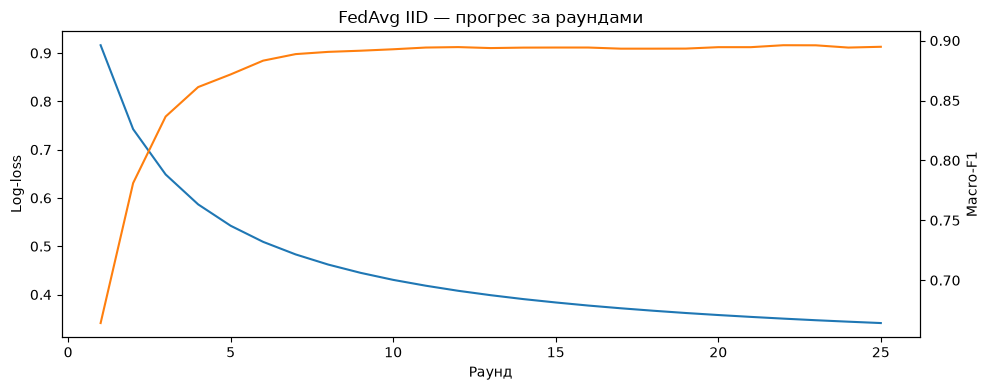

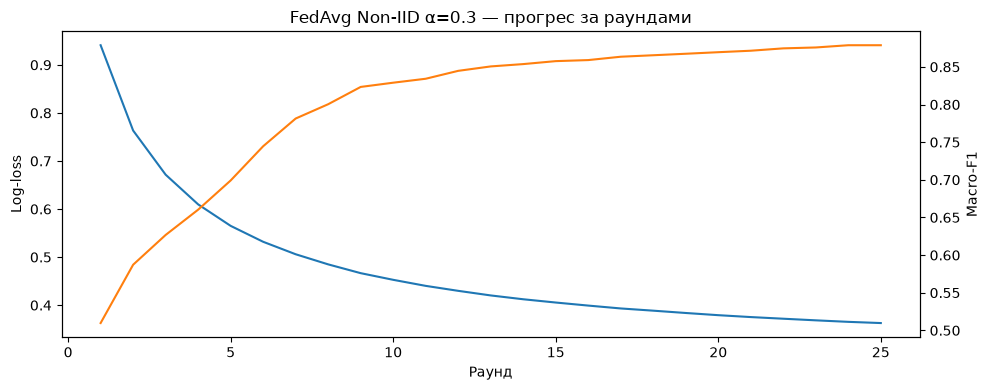

In [11]:
fed_iid_model, fed_iid_history = federated_train(
    X_pool, y_train_pool, iid_clients, X_val, y_val,
    local_epochs=5, rounds=25,
    learning_rate=best_params["learning_rate"],
    reg_lambda=best_params["reg_lambda"],
    batch_size=best_params["batch_size"],
    seed=100
)
fed_noniid_model, fed_noniid_history = federated_train(
    X_pool, y_train_pool, noniid_clients, X_val, y_val,
    local_epochs=5, rounds=25,
    learning_rate=best_params["learning_rate"],
    reg_lambda=best_params["reg_lambda"],
    batch_size=best_params["batch_size"],
    seed=200
)

plot_federated_history(fed_iid_history, "FedAvg IID — прогрес за раундами")
plot_federated_history(fed_noniid_history, "FedAvg Non-IID α=0.3 — прогрес за раундами")

Порівняння графіків FedAvg для IID та Non-IID (α = 0.3) демонструє, що неоднорідність розподілу даних між клієнтами негативно впливає на швидкість збіжності глобальної моделі. В умовах IID LogLoss швидше зменшується, а Macro-F1 раніше досягає стабільного рівня. Натомість у сценарії Non-IID криві навчання змінюються повільніше, що свідчить про складність узгодження локальних моделей клієнтів під час глобальної агрегації.

В обох сценаріях спостерігається покращення якості моделі протягом раундів федеративного навчання. Однак у випадку Non-IID навіть після 25 раундів модель продовжує покращувати результати, що вказує на повільнішу збіжність. Така поведінка пояснюється відмінностями в локальних розподілах класів і характеристик даних між клієнтами.

### 11. Порівняння локальних, глобальних і централізованої моделей
Для локальних моделей кожен клієнт навчає власну модель лише на своєму локальному наборі. Для порівняння їхні параметри оцінюються на Global Test; це оцінювання не впливає на навчання. Така перевірка показує, наскільки модель, навчена на даних одного клієнта, узагальнює на глобальну популяцію.

In [12]:
def train_local_models(X, y, client_indices, params, epochs=60):
    models = []
    for client_id, indices in enumerate(client_indices):
        model = NumpySoftmaxRegression(
            X.shape[1], num_classes, **params,
            random_state=500 + client_id
        )
        model.fit(X[indices], y[indices], epochs=epochs)
        models.append(model)
    return models


local_iid_models = train_local_models(
    X_pool, y_train_pool, iid_clients, best_params
)
local_noniid_models = train_local_models(
    X_pool, y_train_pool, noniid_clients, best_params
)

comparison_rows = []
for name, model in [
    ("Centralized", central_model),
    ("FedAvg IID", fed_iid_model),
    ("FedAvg Non-IID α=0.3", fed_noniid_model)
]:
    comparison_rows.append({"model": name, **evaluate_model(model, X_test, y_test)})

for i, model in enumerate(local_iid_models):
    comparison_rows.append({
        "model": f"Local IID client {i+1}",
        **evaluate_model(model, X_test, y_test)
    })

for i, model in enumerate(local_noniid_models):
    comparison_rows.append({
        "model": f"Local Non-IID client {i+1}",
        **evaluate_model(model, X_test, y_test)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.sort_values("macro_f1", ascending=False).reset_index(drop=True))

,model,accuracy,macro_f1,balanced_accuracy,log_loss
0,Centralized,0.895336,0.905789,0.902599,0.297323
1,FedAvg IID,0.887257,0.893759,0.890779,0.352242
2,Local IID client 3,0.886155,0.891341,0.887234,0.417560
3,Local IID client 4,0.885053,0.890735,0.887441,0.416558
4,Local IID client 6,0.883952,0.888992,0.886049,0.420061
5,Local IID client 5,0.883217,0.887426,0.884966,0.415829
6,Local IID client 10,0.881748,0.886765,0.883675,0.416932
7,Local IID client 7,0.882115,0.886562,0.883032,0.418601
8,Local IID client 2,0.882115,0.885607,0.882258,0.417575
9,Local IID client 8,0.880646,0.885255,0.882269,0.414866


Централізована модель продемонструвала найкращий результат із Macro-F1 = 0.9058 та Accuracy = 0.8953. FedAvg IID показав дещо нижчу якість (Macro-F1 = 0.8938), що свідчить про ефективність федеративної агрегації, хоча вона не повністю відтворює результати централізованого навчання.

Локальні IID-моделі продемонстрували відносно близькі результати між собою, оскільки клієнти мають приблизно однаковий розподіл даних. Натомість локальні Non-IID-моделі показали значно нижчі значення Macro-F1 від 0.2135 до 0.6570. Це пояснюється неоднорідністю локальних наборів даних: окремі клієнти мають недостатньо прикладів деяких класів для побудови якісної багатокласової моделі.

Водночас глобальна модель FedAvg Non-IID досягла Macro-F1 = 0.8787, що суттєво краще за результати окремих локальних моделей. Це демонструє перевагу об'єднання знань клієнтів через федеративну агрегацію. Отже, FedAvg дозволяє компенсувати обмеженість локальних даних і отримати модель, здатну краще узагальнювати результати на глобальній вибірці.

### 12. Експеримент 1. Вплив неоднорідності (α)
Порівнюємо α = 5, 1 і 0.3. Для кожного α заново формуємо клієнтські частини лише з FL Train Pool. Global Test не використовується ні для розподілу, ні для підбору параметрів.

,alpha,accuracy,macro_f1,balanced_accuracy,log_loss
0,5.0,0.887257,0.893521,0.890268,0.354301
1,1.0,0.884686,0.889371,0.885449,0.360900
2,0.3,0.883217,0.889116,0.884148,0.357685


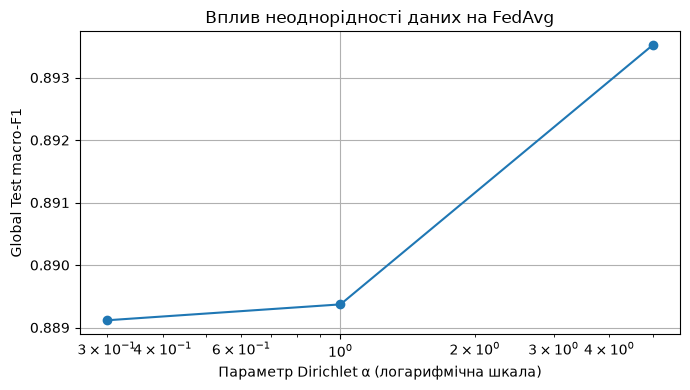

In [13]:
alpha_results = []
alpha_histories = {}

for alpha in [5.0, 1.0, 0.3]:
    clients = make_dirichlet_clients(
        y_train_pool, N_CLIENTS, alpha=alpha,
        seed=RANDOM_STATE + int(alpha * 100)
    )
    model, history = federated_train(
        X_pool, y_train_pool, clients, X_val, y_val,
        local_epochs=5, rounds=25,
        learning_rate=best_params["learning_rate"],
        reg_lambda=best_params["reg_lambda"],
        batch_size=best_params["batch_size"],
        seed=700 + int(alpha * 100)
    )
    alpha_histories[alpha] = history
    alpha_results.append({
        "alpha": alpha,
        **evaluate_model(model, X_test, y_test)
    })

alpha_df = pd.DataFrame(alpha_results).sort_values("alpha", ascending=False)
display(alpha_df)

plt.figure(figsize=(7, 4))
plt.plot(alpha_df["alpha"], alpha_df["macro_f1"], marker="o")
plt.xscale("log")
plt.xlabel("Параметр Dirichlet α (логарифмічна шкала)")
plt.ylabel("Global Test macro-F1")
plt.title("Вплив неоднорідності даних на FedAvg")
plt.grid(True)
plt.tight_layout()
plt.show()


За великого α розподіли клієнтів ближчі до IID, а за малого- більш неоднорідні. Якщо macro-F1 знижується зі зменшенням α, це свідчить, що різні локальні розподіли класів ускладнюють агрегацію. Глобальна модель може поступатися централізованій, оскільки централізоване навчання бачить усі приклади в кожному кроці оптимізації. Водночас глобальна модель може поступатися окремій локальній моделі на конкретному класі або підмножині, але це не означає кращого глобального узагальнення.

### 13. Експеримент 2. Вплив кількості локальних епох E
Порівнюємо E = 1, 5, 10 за однакового IID / Non-IID сценарію та кількості раундів. Client drift - це відхилення локальних параметрів від напрямку, який був би корисним для глобальної задачі. У Non-IID сценарії клієнт оптимізує локальний розподіл, який може суттєво відрізнятися від глобального; більше локальних епох може посилювати цей ефект.

,local_epochs,accuracy,macro_f1,balanced_accuracy,log_loss
0,1,0.828498,0.817116,0.807658,0.526673
1,5,0.878443,0.879542,0.874947,0.369551
2,10,0.882850,0.886636,0.883232,0.343796


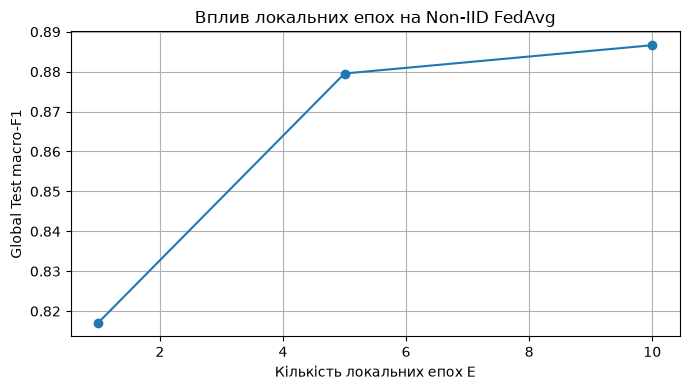

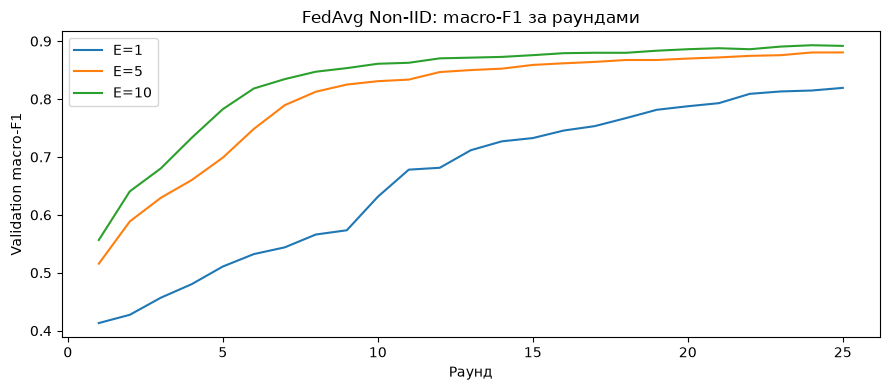

In [14]:
epoch_results = []
epoch_histories = {}

for local_epochs in [1, 5, 10]:
    model, history = federated_train(
        X_pool, y_train_pool, noniid_clients, X_val, y_val,
        local_epochs=local_epochs, rounds=25,
        learning_rate=best_params["learning_rate"],
        reg_lambda=best_params["reg_lambda"],
        batch_size=best_params["batch_size"],
        seed=900 + local_epochs
    )
    epoch_histories[local_epochs] = history
    epoch_results.append({
        "local_epochs": local_epochs,
        **evaluate_model(model, X_test, y_test)
    })

epoch_df = pd.DataFrame(epoch_results)
display(epoch_df)

plt.figure(figsize=(7, 4))
plt.plot(epoch_df["local_epochs"], epoch_df["macro_f1"], marker="o")
plt.xlabel("Кількість локальних епох E")
plt.ylabel("Global Test macro-F1")
plt.title("Вплив локальних епох на Non-IID FedAvg")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
for e, history in epoch_histories.items():
    plt.plot(history["round"], history["val_macro_f1"], label=f"E={e}")
plt.xlabel("Раунд")
plt.ylabel("Validation macro-F1")
plt.title("FedAvg Non-IID: macro-F1 за раундами")
plt.legend()
plt.tight_layout()
plt.show()


Зі збільшенням E клієнти довше навчаються локально перед агрегацією. Це може зменшувати комунікаційні витрати, але на Non-IID даних локальні моделі сильніше пристосовуються до власних розподілів. Якщо якість падає при E=10, це ознака client drift. Оптимальне E залежить від неоднорідності даних і швидкості збіжності.

### 14. Фінальна оцінка на Global Test
Global Test використовується лише тут для остаточного звіту. Наводимо метрики найкращої централізованої моделі та основних FedAvg моделей.

,accuracy,macro_f1,balanced_accuracy,log_loss
model,,,,
Centralized,0.895336,0.905789,0.902599,0.297323
FedAvg IID,0.887257,0.893759,0.890779,0.352242
FedAvg Non-IID α=0.3,0.878443,0.878688,0.873577,0.370166


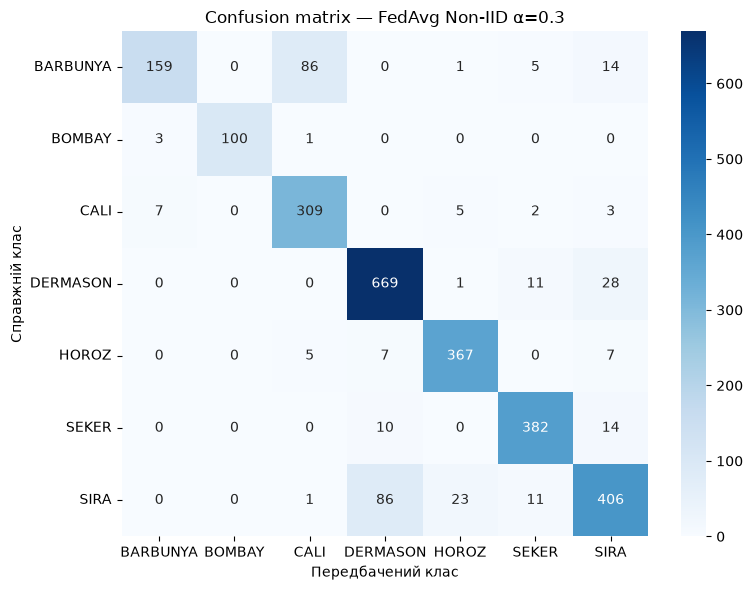

In [15]:
final_rows = []
final_models = {
    "Centralized": central_model,
    "FedAvg IID": fed_iid_model,
    "FedAvg Non-IID α=0.3": fed_noniid_model
}
for name, model in final_models.items():
    final_rows.append({"model": name, **evaluate_model(model, X_test, y_test)})

final_metrics_df = pd.DataFrame(final_rows).set_index("model")
display(final_metrics_df)

show_confusion_matrix(fed_noniid_model, X_test, y_test,
                      "Confusion matrix — FedAvg Non-IID α=0.3")

### 15. Схема розподілу даних та архітектура FedAvg
1. Увесь набір даних спочатку ділиться на FL Train Pool (70%), Global Validation (10%) і Global Test (20%).
2. Відбір ознак і параметри стандартизації навчаються лише на FL Train Pool.
3. Лише FL Train Pool розподіляється між K клієнтами.
4. Сервер зберігає Global Validation / Global Test та глобальні параметри. Клієнти мають лише власні локальні тренувальні дані.
5. Клієнти повертають параметри W і b; сервер виконує зважену агрегацію FedAvg.

### Відповіді на теоретичні питання
1. Чому для багатокласової класифікації використовують softmax? Softmax перетворює оцінки класів на невід'ємні ймовірності, сума яких для одного об'єкта дорівнює 1. Це дозволяє вибрати найбільш імовірний клас.
2. Чому крос-ентропія є природною функцією втрат? Вона вимірює невідповідність між правильною one-hot міткою та прогнозованим розподілом імовірностей. Мінімізація крос-ентропії еквівалентна максимізації правдоподібності.
3. Ridge vs Lasso. Ridge додає штраф λΣw² і зменшує величини ваг; Lasso додає λΣ|w| і може занулювати частину ваг, виконуючи відбір ознак.
4. Чому b зазвичай не регуляризують? Зсув відповідає за базові рівні оцінок класів і не є вагою ознаки; його штрафування може необґрунтовано обмежувати базові ймовірності класів.
5. Що таке Data Leakage? Використання інформації з validation/test у навчанні або підготовці ознак, через що оцінка якості стає надто оптимістичною.
6. Чому не можна підбирати гіперпараметри на test? Тоді рішення починають опосередковано підлаштовуватися під test, і він перестає бути незалежною фінальною перевіркою.
7. Чому scaler навчають лише на train? Щоб середні та дисперсії не містили інформації з validation/test. Після fit ті самі параметри застосовуються до інших наборів.
8. Що таке федеративне навчання та його переваги? Це спосіб спільного навчання, коли дані залишаються у власників/клієнтів, а сервер агрегує оновлення моделей. Переваги: менше централізованого обміну сирими даними, локальний контроль даних, можливість навчання між організаціями/пристроями.
9. Чому сервер не повинен отримувати сирі дані? Щоб зменшити ризики витоку та зберегти локальність даних. Водночас самі градієнти/ваги теж можуть розкривати інформацію, тому для реального FL потрібні додаткові механізми захисту.
10. Чому FedAvg зважує за кількістю прикладів? Клієнт із більшою вибіркою має більший внесок у глобальну емпіричну функцію втрат.
11. Що буде без зважування? Малий клієнт матиме такий самий вплив, як великий, що може спотворити глобальну ціль і погіршити якість.
12. Що таке Non-IID? Дані клієнтів не є незалежними вибірками з однакового розподілу; відрізняються частоти класів або розподіли ознак.
13. Чому FL погіршується на Non-IID? Локальні градієнти можуть вказувати в різні напрямки, тому середнє локальних параметрів гірше наближає централізований крок.
14. Що таке client drift? Відхилення локального навчання від глобально корисного напрямку через відмінність локального розподілу даних.
15. Як E впливає на глобальну модель? Більше локальних епох означає менше обмінів, але сильніше локальне пристосування; на Non-IID це може посилити client drift.
16. Чи може глобальна модель бути гіршою за централізовану? Так. FedAvg має обмежену кількість раундів, локальні кроки й неоднорідність даних; централізоване навчання оптимізує спільну функцію без розбіжності локальних задач.
17. Які метрики краще при дисбалансі класів? Macro-F1 і balanced accuracy дають кожному класу однакову вагу; також корисні confusion matrix та log-loss. Accuracy варто наводити разом із ними, а не окремо.

### Висновок
У роботі досліджено Dry Bean Dataset і реалізовано багатокласову логістичну регресію засобами NumPy. Дані розділено на FL Train Pool, Global Validation і Global Test до масштабування; відбір ознак і стандартизація виконані лише на FL Train Pool. Реалізовано централізоване навчання, розподіл IID та Non-IID за Діріхле, FedAvg зі зважуванням за кількістю локальних прикладів, а також експерименти з α та кількістю локальних епох.